# 3) Creating primaries analytically: main sequence + black hole candidates

In this notebook I will use a simple prescription for MS+BD binaries to generate the primaries and then use my `Wrapper` to compute rates of getting orbit solutions using the "DR4" BH3-orbit solution cuts

In [1]:
import numpy as np
from matplotlib import pylab as plt
from scipy.special import gammainc, gamma
from astropy.table import Table

In [ ]:
from Wrapper import SimulateAstrometry, style, utils
from Wrapper.SimulateAstrometry import simulate_population_astrometry as simpopast

## Generate primaries

In [3]:
N = 100000

In [4]:
k, theta = 2.006, 0.557 #2.4, 0.4 

def p(x):
    """Gamma probability density with shape k and scale theta."""    
    return x** (k - 1)* np.exp(-x/ theta)/ (gamma(k) * theta**k)

def cdf(x):
    """Gamma cumulative distribution function"""
    return gammainc(k, x/ theta)

In [5]:
rng = np.random.default_rng()
Mstar_vals = rng.gamma(shape=k, scale=theta, size=N) # [Msun] primaries are assigned from this gamma function that peaks near 1

In [6]:
Tsun = 5800 # [K]
def LT_model(M):
    L = M**3.5 # [Lsun]
    R = M**0.8 # [Rsun]
    T = Tsun*(L**0.25)*(1/R)**0.5 # [K] (from Stefan-Bolzmann law)
    return L,T,R

def g_model(M,R):
    return 274*M*R**(-2.) # [m/s^2] (surface gravity def)

In [7]:
L_vals, T_vals, R_vals = LT_model(Mstar_vals) # assign luminosity, temperature, and radius based on mass
g_vals = g_model(Mstar_vals, R_vals) # then get the logg

## Assign gaia magnitudes

${\tt Gaia}$ published the package `gdr3bcg` which can tell you the bolometric correction given stellar parameters. 

We can therefore work backwards: luminosity can be easily converted to bolometric luminosity and then the `gdr3bcg` correction can get you the DR3 G-band magnitude

This correcponds to our sources having such an apparent magnitude at 10pc. We can then use my `Wrapper` to change the distance distribution

In [8]:
import gdr3bcg.bcg as bcg
bcg_table = bcg.BolometryTable()

/home/bepennell/research/GaiamockWrapper/.wrapperenv/lib/python3.10/site-packages/gdr3bcg/bcg.py:43: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  table=pd.read_table(file, delim_whitespace=True, names=["teff", "logg","metal","alpha","bc"],dtype={'teff':np.float64,'logg':np.float64,'metal':np.float64,'alpha':np.float64,'bc':np.float64})


In [9]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm

M_bol_sun = 4.74
m_bol = M_bol_sun - 2.5 * np.log10(L_vals) #  convert luminosity (in Lsun) to absolute bolometric magnitude

bol_corrs = np.array(Parallel(n_jobs=-1)(delayed(bcg_table.computeBc)([T_vals[i], np.log10(g_vals[i]), 0, 0])
                                        for i in tqdm(range(len(T_vals)), desc="Computing bolometric corrections"))) # get the correction to gaia g-band magnitude
m_bol_corr = m_bol - bol_corrs # make the correction to absolute magnitude in g-band

Computing bolometric corrections:   0%|          | 0/100000 [00:00<?, ?it/s]

In [10]:
# construct the table that will be used in my `Wrapper`
outtab = Table()
outtab["mass"] = Mstar_vals
outtab["luminosity"] = L_vals
outtab["Teff"] = T_vals
outtab["logg"] = np.log10(g_vals)
outtab["phot_g_mean_mag"] = m_bol_corr # apparent magnitude at 10pc (absolute magnitude)
outtab["parallax"] = 1000/10 # absolute magnitude places them at 10pc
# assign random sky positions to the final table with a proper motion limit of 10 mas/yr
utils.random_sky_positions(outtab, proper_motion_limit=10) 

In [11]:
outtab.write("./data/MSBH_toy_model_parent_sample.fits", format="fits", overwrite=True)

## Simulate some companions

- eccentricity: uniform
- period: (log?) flat between 65 and 4000d
- companions: uniform between 8.5 and 10

In [3]:
parent_sample = Table.read("./data/MSBH_toy_model_parent_sample.fits", format="fits")

In [ ]:
objs, astrometry_results = simpopast(object_count=100000, catalogue=parent_sample,
                                        astrometry_function=SimulateAstrometry.gw.dr4_astrometric_pipeline, 
                                        period_model=utils.uniform_distribution, period_kwargs={"lims": (65, 4000)}, # uniform distribution of periods
                                        eccentricity_model=utils.uniform_distribution, ecc_kwargs={"lims": (0.1, 0.95)}, # uniform eccentricity
                                        companion_mass_model=utils.uniform_distribution, m_kwargs={"lims": (8.5, 10)}, # uniform distribution of BH masses
                                        compute_mass_ratios=False, # we want to directly sample companion masses
                                        flux_ratio_model=utils.constant_distribution, f_kwargs={"value": 0}, # companions are dark, so flux is 0
                                        reassign_parallaxes=True, plx_kwargs={"dist_range": (100, 1000)}, # set the distance to be 0.1-1 kpc
                                        return_fits=True, return_statistics=True, n_jobs=-1)
utils.postproces_solution_type(objs, astrometry_results)
processed_res = utils.postprocess_fits(astrometry_results)

In [14]:
objs.write("./data/MSBH_toy_model_simulated_sample.fits", format="fits", overwrite=True)

In [30]:
processed_res.write("./data/MSBH_toy_model_simulated_res.fits", format="fits", overwrite=True)

In [13]:
objs = Table.read("./data/MSBH_toy_model_simulated_sample.fits", format="fits")
processed_res = Table.read("./data/MSBH_toy_model_simulated_res.fits", format="fits")

In [14]:
reasonable_sources = objs[objs["phot_g_mean_mag"] < 19]
reasonable_res = processed_res[objs["phot_g_mean_mag"] < 19]

nss_mask = reasonable_sources["solution_type"] == 12

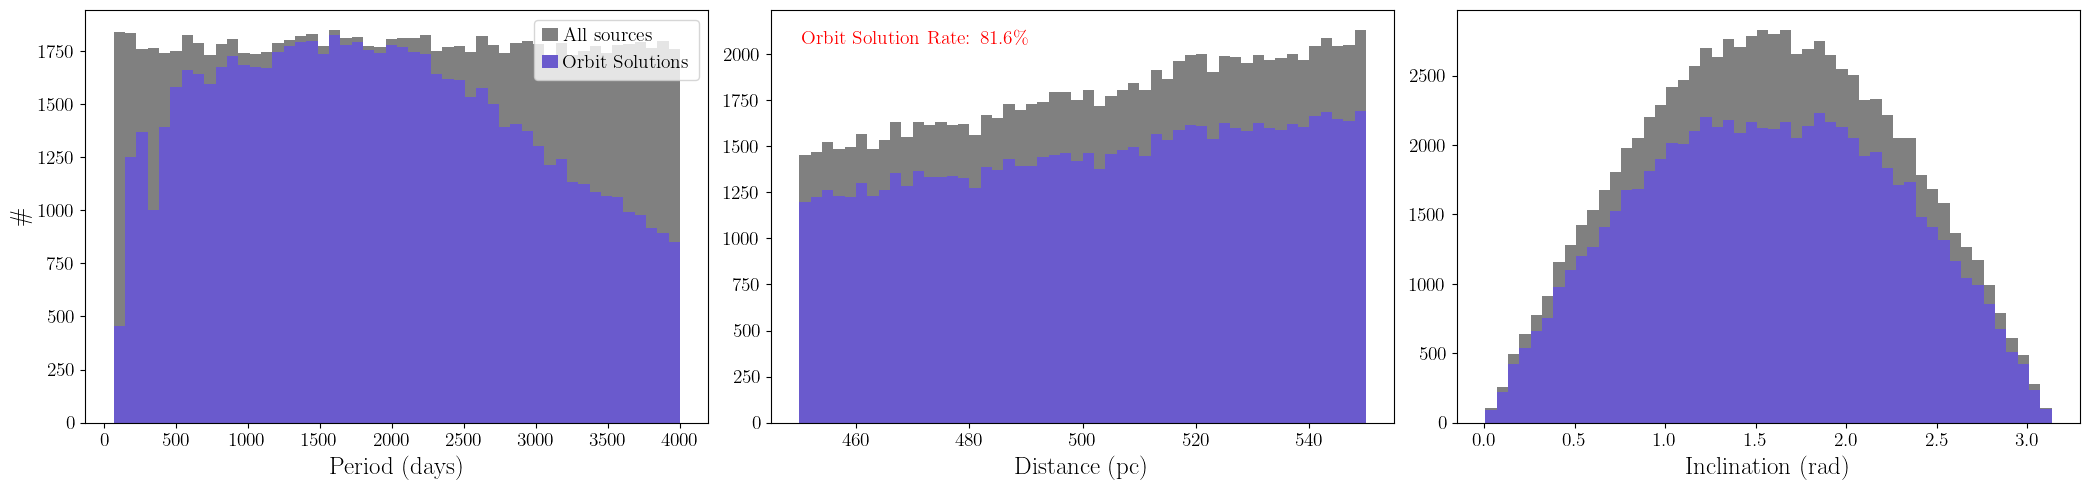

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(21, 5))

rate = len(reasonable_sources[nss_mask])/len(reasonable_sources)*100

ax = axs[0]
tbins = ax.hist(reasonable_sources["period"], bins=50, color="grey", label="All sources")
ax.hist(reasonable_sources[nss_mask]["period"], bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.legend(frameon=True)
ax.set_xlabel("Period (days)")
ax.set_ylabel("\#")

ax = axs[1]
tbins = ax.hist(1000/reasonable_sources["parallax"], bins=50, color="grey", label="All sources")
ax.hist(1000/reasonable_sources[nss_mask]["parallax"], bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.set_xlabel("Distance (pc)")
ax.text(0.05, 0.95, f"Orbit Solution Rate: {rate:.1f}\%", color="red", transform=ax.transAxes, fontsize=14, verticalalignment='top')

ax = axs[2]
tbins = ax.hist(reasonable_sources["inc"], bins=50, color="grey", label="All sources")
ax.hist(reasonable_sources[nss_mask]["inc"], bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.set_xlabel("Inclination (rad)")

plt.tight_layout()
plt.show()

## just some diagnostic plots so we can assure ourselves the magnitude business is actually working

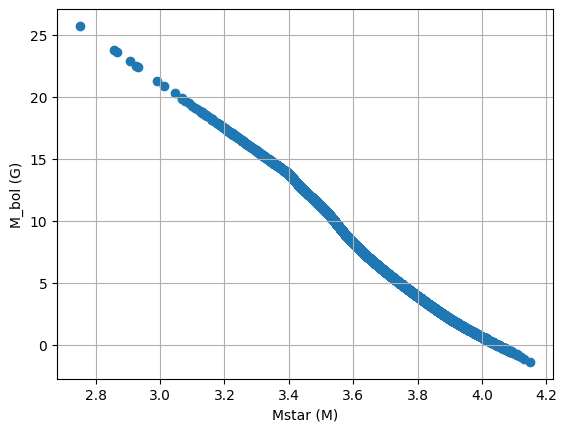

In [65]:
plt.scatter(np.log10(T_vals), m_bol_corr)
plt.xlabel("Mstar (M)")
plt.ylabel("M_bol (G)")
plt.grid(True)
plt.show()

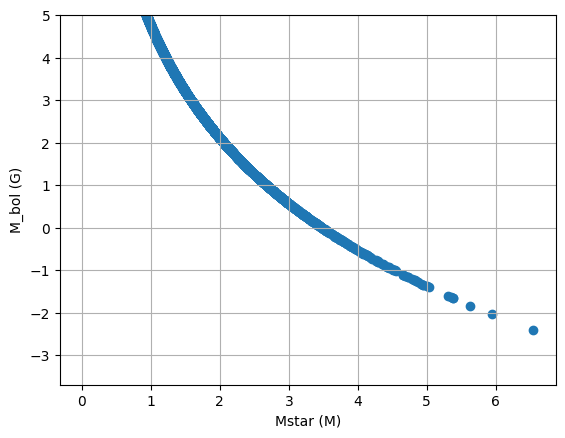

In [66]:
plt.scatter(Mstar_vals, m_bol)
plt.xlabel("Mstar (M)")
plt.ylabel("M_bol (G)")
plt.grid(True)
plt.ylim(top=5)
plt.show()

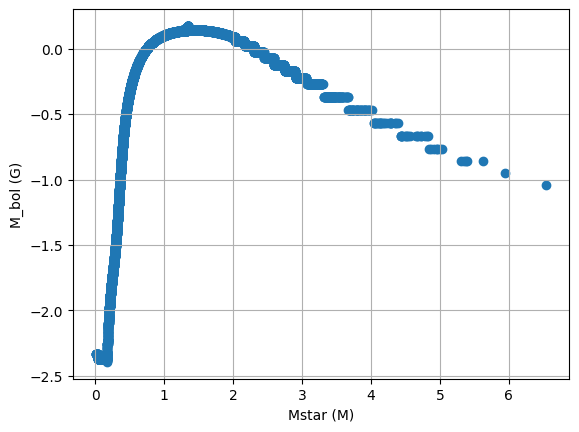

In [67]:
plt.scatter(Mstar_vals, bol_corrs)
plt.xlabel("Mstar (M)")
plt.ylabel("M_bol (G)")
plt.grid(True)
plt.show()

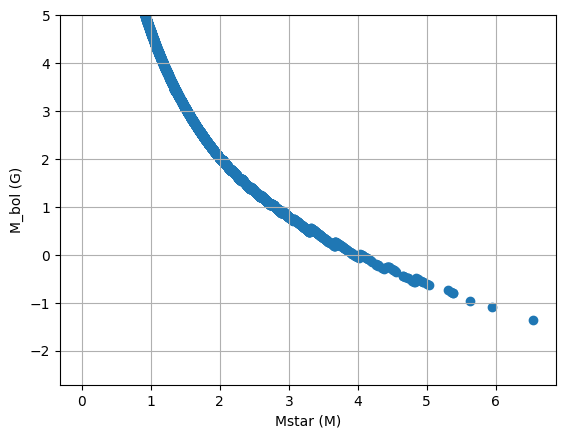

In [68]:
plt.scatter(Mstar_vals, m_bol_corr)
plt.xlabel("Mstar (M)")
plt.ylabel("M_bol (G)")
plt.grid(True)
plt.ylim(top=5)
plt.show()